In [1]:
from datetime import timedelta
from joblib import load
from mplsoccer import Pitch
from socceraction.atomic.vaep.formula import value
from statsbombpy import sb
from tqdm import tqdm
import ast
import duckdb
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import seaborn as sns
import socceraction.atomic.spadl as atomicspadl

In [2]:
actions_data = []

for actions_file in os.listdir("../data/actions"):
    actions_data.append(
        pd.read_parquet(
            f"../data/actions/{actions_file}",
            engine="fastparquet"
        )
    )

actions_df = atomicspadl.add_names(pd.concat(actions_data))

In [3]:
events_data = []

for events_file in os.listdir("../data/events"):
    events_data.append(
        pd.read_parquet(
            f"../data/events/{events_file}",
            engine="fastparquet"
        )
    )

events_df = pd.concat(events_data)

KeyboardInterrupt: 

In [ ]:
max_match_mins_df = events_df[events_df["period"] != 5][["match_id", "minute"]].groupby("match_id").agg({"minute": "max"}).reset_index()

In [ ]:
players = {}

for match_id in tqdm(max_match_mins_df["match_id"].tolist(), desc="Processing Matches"):

    for data in sb.lineups(match_id=match_id).values():
        
        for player_id, position_data in zip(data.get("player_id").tolist(), data.get("positions").tolist()):

            if len(position_data) == 0:
                start_time = timedelta(seconds=0)
                end_time = timedelta(seconds=0)

            if len(position_data) != 0:
                start_minutes, start_seconds = map(int, position_data[0].get("from").split(":"))
                start_time = timedelta(minutes=start_minutes, seconds=start_seconds)

            if len(position_data) == 1:

                if not position_data[0].get("to"):
                    end_time = timedelta(minutes=max_match_mins_df[max_match_mins_df["match_id"] == match_id]["minute"].item())
                else:
                    end_minutes, end_seconds = map(int, position_data[0].get("to").split(":"))
                    end_time = timedelta(minutes=end_minutes, seconds=end_seconds)
            
            if len(position_data) > 1:
                if not position_data[-1].get("to"):
                    end_time = timedelta(minutes=max_match_mins_df[max_match_mins_df["match_id"] == match_id]["minute"].item())
                else:
                    end_minutes, end_seconds = map(int, position_data[-1].get("to").split(":"))
                    end_time = timedelta(minutes=end_minutes, seconds=end_seconds)

            if player_id not in players:
                players[player_id] = timedelta(seconds=0)
            
            time_played = end_time - start_time
            players[player_id] += time_played

Processing Matches: 100%|██████████| 292/292 [02:45<00:00,  1.76it/s]


In [ ]:
X_train = load("../data/modelling/train/X_train_dict.pkl")
X_test = load("../data/modelling/test/X_test_dict.pkl")
y_train = load("../data/modelling/train/targets_train_dict.pkl")
y_test = load("../data/modelling/test/targets_test_dict.pkl")

In [ ]:
id_cols = ["game_id", "action_id"]

manual_spatial_feature_prefixes = [
    "actor_minimum_distance_to_opponent",
    "actor_minimum_distance_to_teammate",
    "actor_mean_distance_to_opponent",
    "actor_mean_distance_to_teammate",
    "actor_stdev_distance_to_opponent",
    "actor_stdev_distance_to_teammate",
    "number_of_opponents_within_radius_of_actor",
    "number_of_teammates_within_radius_of_actor",
    "opponent_convex_hull_area",
    "teammate_convex_hull_area",
]

manual_spatial_feature_cols = [
    c for c in X_train["all"].columns
    if any(c.startswith(prefix) for prefix in manual_spatial_feature_prefixes)
]

spatial_embedding_feature_cols = [
    c for c in X_train["all"].columns
    if c.startswith("spatial_embedding_")
]

baseline_feature_cols = [
    c for c in X_train["all"].columns
    if (
        c not in manual_spatial_feature_cols
        and c not in spatial_embedding_feature_cols
    )
]

In [ ]:
atomic_actions_all_df = pd.concat([X_train["all"], X_test["all"]])
atomic_actions_all_df["concedes"] = pd.concat([y_train["concedes"].drop(["game_id", "action_id"], axis=1), y_test["concedes"].drop(["game_id", "action_id"], axis=1)])
atomic_actions_all_df["scores"] = pd.concat([y_train["scores"].drop(["game_id", "action_id"], axis=1), y_test["scores"].drop(["game_id", "action_id"], axis=1)])

del X_train, X_test, y_train, y_test

<positron-console-cell-8>:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
<positron-console-cell-8>:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`


In [ ]:
concedes_classifier_model = load("../models/classifiers/xgboost_embeddings_concedes.pkl")
scores_classifier_model = load("../models/classifiers/xgboost_manual_scores.pkl")

In [ ]:
preds_df = atomic_actions_all_df[["game_id", "action_id"]].reset_index(drop=True)

preds_df["pconcedes"] = concedes_classifier_model.predict_proba(
    atomic_actions_all_df[baseline_feature_cols + spatial_embedding_feature_cols].drop(["game_id", "action_id"], axis=1)
)[:, 1]

preds_df["pscores"] = scores_classifier_model.predict_proba(
    atomic_actions_all_df[baseline_feature_cols + manual_spatial_feature_cols].drop(["game_id", "action_id"], axis=1)
)[:, 1]

atomic_actions_df = preds_df.merge(actions_df, on=["game_id", "action_id"], how="left")

In [ ]:
atomic_actions_df[["offensive_value", "defensive_value", "vaep_value"]] = value(
    atomic_actions_df,
    atomic_actions_df["pscores"], 
    atomic_actions_df["pconcedes"]
)

In [ ]:
atomic_actions_df[[
    "game_id", "action_id",
     "offensive_value", "defensive_value", 
     "vaep_value"
]].to_parquet("../data/vaep/atomic_actions_with_vaep.parquet", compression="zstd", index=False)

In [ ]:
mins_played_df = pd.DataFrame({k: v.total_seconds() / 60 for k, v in players.items()}.items(), columns=["player_id", "minutes_played"])

In [ ]:
mins_played_df = mins_played_df[mins_played_df["minutes_played"] > 0]

In [ ]:
total_vaep_value_df = atomic_actions_df[["player_id", "vaep_value"]].groupby("player_id").agg(vaep_value=("vaep_value", "sum"), number_of_actions=("player_id", "size")).reset_index()

In [ ]:
players_mins_and_vaep_df = pd.merge(
    mins_played_df,
    total_vaep_value_df,
    on="player_id",
    how="left"
)

In [ ]:
players_mins_and_vaep_df["90s_played"] = players_mins_and_vaep_df["minutes_played"] / 90

In [ ]:
players_mins_and_vaep_df["actions_per_90"] = players_mins_and_vaep_df["number_of_actions"] / players_mins_and_vaep_df["90s_played"]
players_mins_and_vaep_df["vaep_per_90"] = players_mins_and_vaep_df["vaep_value"] / players_mins_and_vaep_df["90s_played"]

In [ ]:
players_mins_and_vaep_df["vaep_per_action"] = players_mins_and_vaep_df["vaep_value"] / players_mins_and_vaep_df["number_of_actions"]

In [ ]:
vaep_player_data_df = pd.merge(
    players_mins_and_vaep_df,
    events_df[["player_id", "player", "position"]],
    on="player_id",
    how="left"
).drop_duplicates().dropna()

In [ ]:
vaep_player_data_with_competition_df = pd.merge(
    vaep_player_data_df,
    events_df[["player_id", "competition"]],
    on="player_id",
    how="left"
).drop_duplicates()

In [ ]:
vaep_player_data_with_competition_df["player_gender"] = vaep_player_data_with_competition_df["competition"].str.contains("Women's", case=False, na=False).map({True: "female", False: "male"})
vaep_player_data_with_competition_df = vaep_player_data_with_competition_df[vaep_player_data_with_competition_df["position"] != "Goalkeeper"]
vaep_player_data_with_competition_df = vaep_player_data_with_competition_df.drop(columns=["position"], axis=1).drop_duplicates()

In [ ]:
vaep_to_actions_plot_df = vaep_player_data_with_competition_df[
    vaep_player_data_with_competition_df["90s_played"] > 3
][["player", "player_gender", "90s_played", "actions_per_90", "vaep_per_action"]].drop_duplicates()

vaep_to_actions_plot_df = vaep_to_actions_plot_df.reset_index(drop=True)

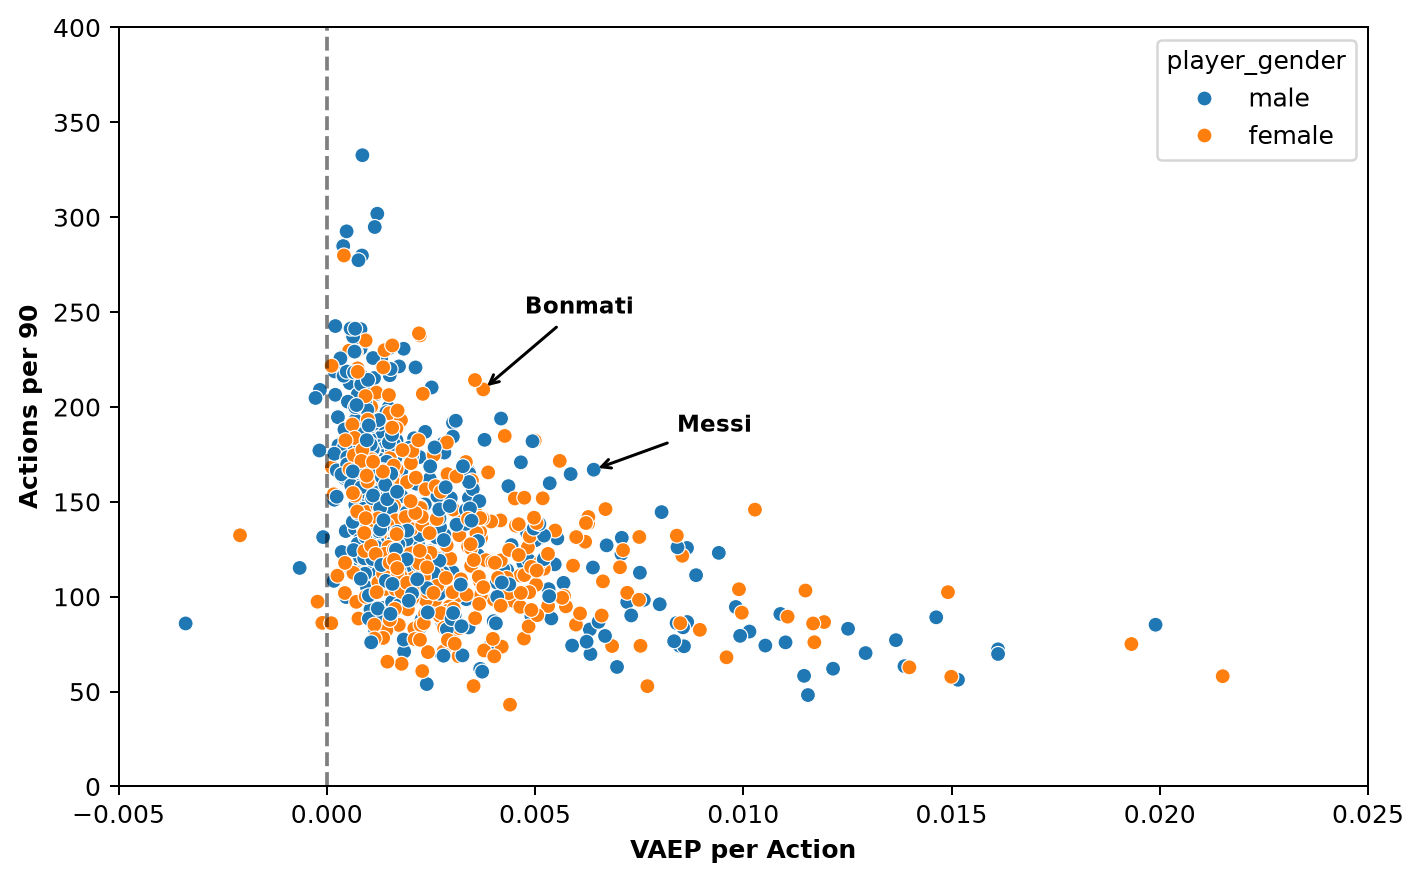

In [ ]:
plt.figure(figsize=(8,5), constrained_layout=True)

sns.scatterplot(
    data=vaep_to_actions_plot_df,
    x="vaep_per_action",
    y="actions_per_90",
    hue="player_gender"
)

plt.axvline(x=0, color="black", linestyle="--", alpha=0.5)

plt.xlim(-0.005, 0.025)
plt.xlabel("VAEP per Action", fontweight="bold")

plt.ylim(0, 400)
plt.ylabel("Actions per 90", fontweight="bold")

messi_row = vaep_to_actions_plot_df[
    vaep_to_actions_plot_df["player"] == "Lionel Andrés Messi Cuccittini"
]

messi_row = messi_row.iloc[0]
plt.annotate(
    "Messi",
    xy=(messi_row["vaep_per_action"], messi_row["actions_per_90"]),
    xytext=(messi_row["vaep_per_action"] + 0.002, messi_row["actions_per_90"] + 20),
    arrowprops=dict(arrowstyle="->", color="black", lw=1.2),
    fontsize=9,
    fontweight="bold"
)

bonmati_row = vaep_to_actions_plot_df[
    vaep_to_actions_plot_df["player"] == "Aitana Bonmati Conca"
]

bonmati_row = bonmati_row.iloc[0]
plt.annotate(
    "Bonmati",
    xy=(bonmati_row["vaep_per_action"], bonmati_row["actions_per_90"]),
    xytext=(bonmati_row["vaep_per_action"] + 0.001, bonmati_row["actions_per_90"] + 40),
    arrowprops=dict(arrowstyle="->", color="black", lw=1.2),
    fontsize=9,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig("../reports/dissertation/figures/vaep_per_action_actions_per_90.png", dpi=300)
plt.show()

In [ ]:
player_ratings_df = (
    vaep_player_data_with_competition_df.groupby(["player_id", "player", "player_gender"], as_index=False)
      .agg(
          minutes_played=("minutes_played", "first"),
          total_vaep=("vaep_value", "first")
      )
)

player_ratings_df["rating"] = (
    90 * player_ratings_df["total_vaep"] /
    player_ratings_df["minutes_played"]
)

player_ratings_df = player_ratings_df[
    ["player_id", "player", "player_gender",  "minutes_played", "rating"]
].sort_values("rating", ascending=False)

conn = duckdb.connect("../data/reep-register-v1.duckdb")

statsbomb_id_to_transfermarkt_id_mapping_df = conn.sql("""
SELECT
    sb.external_id AS statsbomb_player_id,
    tm.external_id AS transfermarkt_player_id,
    p.label AS player
FROM bridges sb
JOIN bridges tm
    ON sb.reep_id = tm.reep_id
JOIN players p
    ON p.reep_id = sb.reep_id
WHERE sb.provider = 'statsbomb'
  AND tm.provider = 'transfermarkt';
""").df()

conn.close()

statsbomb_id_to_transfermarkt_id_mapping_df["statsbomb_player_id"] = statsbomb_id_to_transfermarkt_id_mapping_df["statsbomb_player_id"].astype(int)
statsbomb_id_to_transfermarkt_id_mapping_df["transfermarkt_player_id"] = statsbomb_id_to_transfermarkt_id_mapping_df["transfermarkt_player_id"].astype(int)

player_ratings_df = player_ratings_df.merge(
    statsbomb_id_to_transfermarkt_id_mapping_df.drop("player", axis=1),
    left_on="player_id",
    right_on="statsbomb_player_id",
    how="left"
)

transfermarkt_player_values_df = pd.read_csv("../data/player_valuations.csv", usecols=["date", "player_id", "market_value_in_eur"])

transfermarkt_player_values_df["date"] = pd.to_datetime(transfermarkt_player_values_df["date"], format="mixed")

transfermarkt_player_values_df = transfermarkt_player_values_df[transfermarkt_player_values_df["date"] > "2025-08-01"]

player_ratings_df = pd.merge(
    player_ratings_df,
    transfermarkt_player_values_df,
    left_on="transfermarkt_player_id",
    right_on="player_id",
    how="left"
).sort_values("date", ascending=True).drop(["player_id_y", "date"], axis=1).drop_duplicates(subset="player_id_x", keep="last")

player_ratings_df.drop("statsbomb_player_id", inplace=True, axis=1)

player_ratings_sufficient_playtime_df = player_ratings_df[player_ratings_df["minutes_played"] >= 270]

player_ratings_male_df = player_ratings_sufficient_playtime_df[player_ratings_sufficient_playtime_df["player_gender"] == "male"]
player_ratings_female_df = player_ratings_sufficient_playtime_df[player_ratings_sufficient_playtime_df["player_gender"] == "female"]

In [ ]:
(
    player_ratings_male_df[["player", "minutes_played", "market_value_in_eur", "rating"]]
    .sort_values("rating", ascending=False)
    .head(10)
    .to_parquet(
        "../results/top10_vaep_player_ratings_male.parquet", 
        compression="zstd", 
        index=False
    )
)

In [ ]:
(
    player_ratings_female_df[["player", "minutes_played", "rating"]]
    .sort_values("rating", ascending=False)
    .head(10)
    .to_parquet(
        "../results/top10_vaep_player_ratings_female.parquet", 
        compression="zstd", 
        index=False
    )
)

In [ ]:
from scipy.stats import spearmanr
from scipy.stats import linregress

player_rating_market_value_corr_df = player_ratings_male_df.dropna()

rho, p = spearmanr(
    player_rating_market_value_corr_df["rating"],
    player_rating_market_value_corr_df["market_value_in_eur"]
)

print(f"rho: {rho}, p: {p}")

rho: 0.11574160938276076, p: 0.01981191970003415


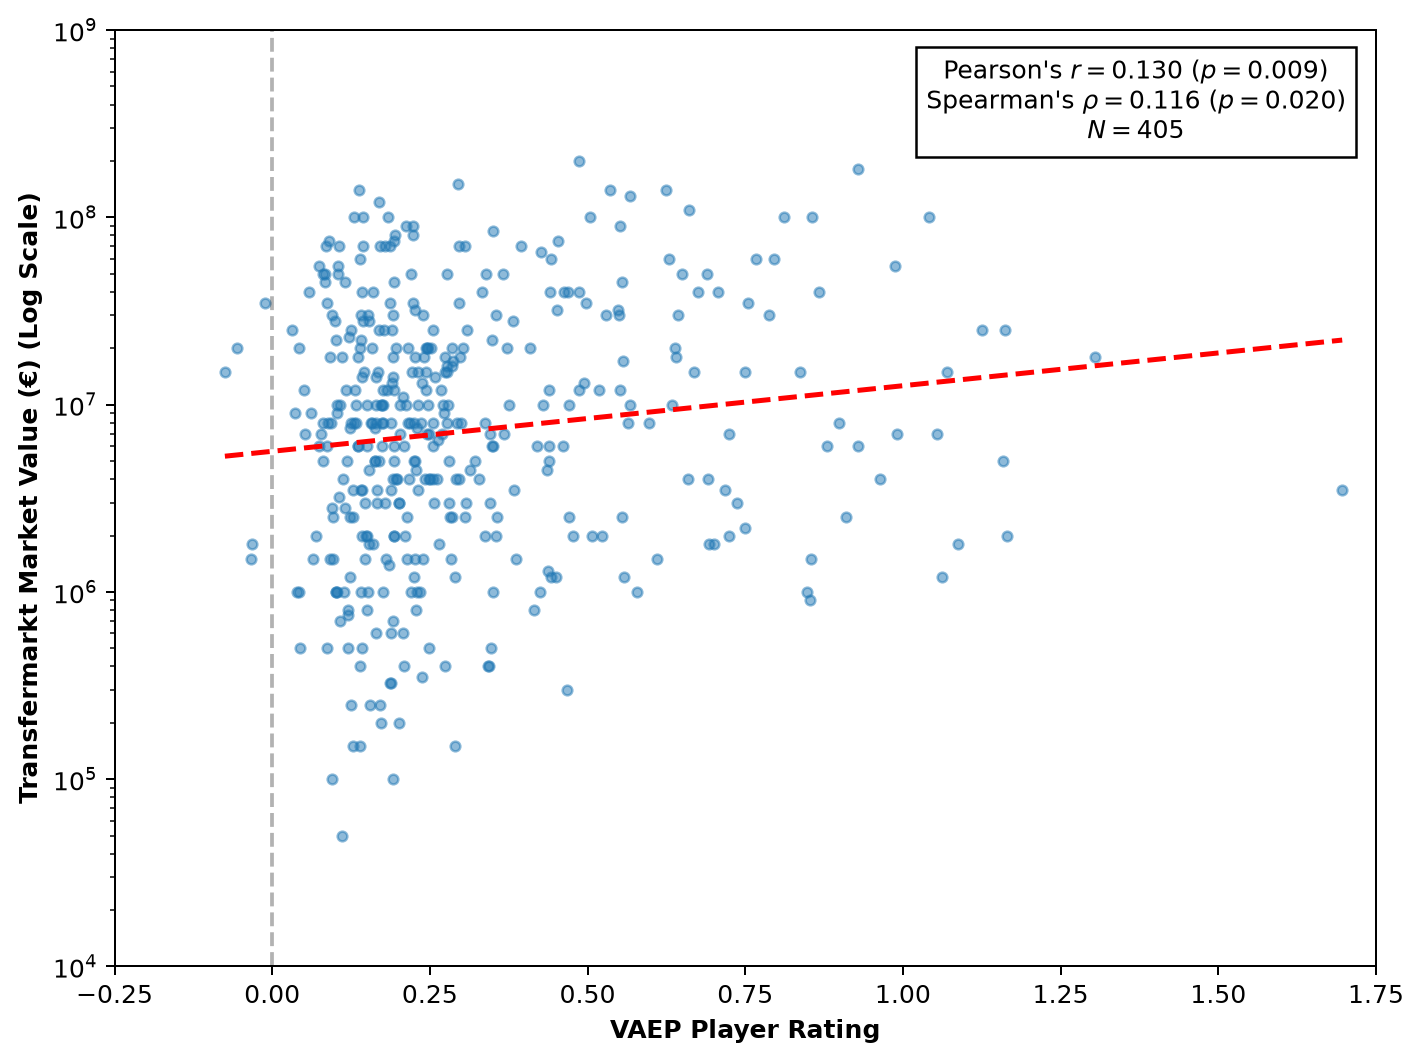

In [ ]:
x = player_rating_market_value_corr_df["rating"]
y = np.log10(player_rating_market_value_corr_df["market_value_in_eur"])

slope, intercept, r, p_pearson, stderr = linregress(x, y)

plt.figure(figsize=(8,6))

plt.scatter(
    x,
    player_rating_market_value_corr_df["market_value_in_eur"],
    alpha=0.5,
    s=15
)

x_line = np.linspace(x.min(), x.max(), 100)
y_line = 10 ** (intercept + slope * x_line)

plt.plot(x_line, y_line, linewidth=2, linestyle="--", color="red")

rho, p_spearman = spearmanr(
    player_rating_market_value_corr_df["rating"],
    player_rating_market_value_corr_df["market_value_in_eur"]
)

plt.text(
    0.81, 0.875,
    f"Pearson's " + rf"$r = {r:.3f}$ " + rf"$\left(p = {p_pearson:.3f}\right)$" + "\n" + f"Spearman's " + rf"$\rho = {rho:.3f}$ " + rf"$\left(p = {p_spearman:.3f}\right)$" + "\n" + rf"$N = {player_rating_market_value_corr_df.shape[0]}$",
    transform=plt.gca().transAxes,
    ha="center",
    va="bottom",
    bbox=dict(facecolor="white", alpha=1)
)

plt.xlim(-0.25, 1.75)

plt.yscale("log")
plt.ylim(1e4, 1e9)

plt.axvline(x=0, color="black", linestyle="--", alpha=0.3)

plt.xlabel("VAEP Player Rating", fontweight="bold")
plt.ylabel("Transfermarkt Market Value (€) (Log Scale)", fontweight="bold")

plt.tight_layout()
plt.savefig("../reports/dissertation/figures/vaep_rating_market_value_scatterplot.png", dpi=300)
plt.show()

In [ ]:
manual_spatial_feature_prefixes = [
    "actor_minimum_distance_to_opponent",
    "actor_minimum_distance_to_teammate",
    "actor_mean_distance_to_opponent",
    "actor_mean_distance_to_teammate",
    "actor_stdev_distance_to_opponent",
    "actor_stdev_distance_to_teammate",
    "number_of_opponents_within_radius_of_actor",
    "number_of_teammates_within_radius_of_actor",
    "opponent_convex_hull_area",
    "teammate_convex_hull_area",
]

manual_spatial_feature_cols = [
    c for c in atomic_actions_all_df.columns
    if any(c.startswith(prefix) for prefix in manual_spatial_feature_prefixes)
]

spatial_embedding_feature_cols = [
    c for c in atomic_actions_all_df.columns
    if c.startswith("spatial_embedding_")
]

baseline_feature_cols = [
    c for c in atomic_actions_all_df.columns
    if (
        c not in manual_spatial_feature_cols
        and c not in spatial_embedding_feature_cols
    )
]

feature_sets = {
    "baseline": baseline_feature_cols,
    "manual": baseline_feature_cols + manual_spatial_feature_cols,
    "embeddings": baseline_feature_cols + spatial_embedding_feature_cols,
    "all": baseline_feature_cols + manual_spatial_feature_cols + spatial_embedding_feature_cols,
}

In [ ]:
concedes_baseline_classifier_model = load("../models/classifiers/xgboost_baseline_concedes.pkl")
scores_baseline_classifier_model = load("../models/classifiers/xgboost_baseline_scores.pkl")
concedes_manual_classifier_model = load("../models/classifiers/xgboost_manual_concedes.pkl")
scores_manual_classifier_model = load("../models/classifiers/xgboost_manual_scores.pkl")
concedes_embeddings_classifier_model = load("../models/classifiers/xgboost_embeddings_concedes.pkl")
scores_embeddings_classifier_model = load("../models/classifiers/xgboost_embeddings_scores.pkl")
concedes_all_classifier_model = load("../models/classifiers/xgboost_all_concedes.pkl")
scores_all_classifier_model = load("../models/classifiers/xgboost_all_scores.pkl")

In [ ]:
concedes_lr_classifier_model = load("../models/classifiers/logistic_regression_baseline_concedes.pkl")
concedes_rf_classifier_model = load("../models/classifiers/random_forest_baseline_concedes.pkl")
concedes_catboost_classifier_model = load("../models/classifiers/catboost_baseline_concedes.pkl")
concedes_xgboost_classifier_model = load("../models/classifiers/xgboost_baseline_concedes.pkl")

scores_lr_classifier_model = load("../models/classifiers/logistic_regression_baseline_scores.pkl")
scores_rf_classifier_model = load("../models/classifiers/random_forest_baseline_scores.pkl")
scores_catboost_classifier_model = load("../models/classifiers/catboost_baseline_scores.pkl")
scores_xgboost_classifier_model = load("../models/classifiers/xgboost_baseline_scores.pkl")

In [ ]:
# XGBoost models: compare feature sets
xgb_models = {
    "baseline": {
        "concedes": concedes_baseline_classifier_model,
        "scores": scores_baseline_classifier_model,
    },
    "manual": {
        "concedes": concedes_manual_classifier_model,
        "scores": scores_manual_classifier_model,
    },
    "embeddings": {
        "concedes": concedes_embeddings_classifier_model,
        "scores": scores_embeddings_classifier_model,
    },
    "all": {
        "concedes": concedes_all_classifier_model,
        "scores": scores_all_classifier_model,
    },
}

# Classifier models: compare classifier techniques using baseline features
classifier_models = {
    "logistic_regression": {
        "concedes": concedes_lr_classifier_model,
        "scores": scores_lr_classifier_model,
    },
    "random_forest": {
        "concedes": concedes_rf_classifier_model,
        "scores": scores_rf_classifier_model,
    },
    "catboost": {
        "concedes": concedes_catboost_classifier_model,
        "scores": scores_catboost_classifier_model,
    },
    "xgboost": {
        "concedes": concedes_xgboost_classifier_model,
        "scores": scores_xgboost_classifier_model,
    },
}

preds_df = atomic_actions_all_df[["game_id", "action_id"]].copy()

# ------------------------------------------------------------
# XGBoost predictions for each feature set
# ------------------------------------------------------------
for feature_set, cols in feature_sets.items():

    X = atomic_actions_all_df[cols].drop(
        ["game_id", "action_id", "concedes", "scores"],
        axis=1
    )

    preds_df[f"pconcedes_{feature_set}"] = (
        xgb_models[feature_set]["concedes"].predict_proba(X)[:, 1]
    )

    preds_df[f"pscores_{feature_set}"] = (
        xgb_models[feature_set]["scores"].predict_proba(X)[:, 1]
    )

# ------------------------------------------------------------
# Baseline-feature predictions for each classifier technique
# ------------------------------------------------------------
baseline_cols = feature_sets["baseline"]

X_baseline = atomic_actions_all_df[baseline_cols].drop(
    ["game_id", "action_id", "concedes", "scores"],
    axis=1
)

for classifier, models in classifier_models.items():

    preds_df[f"pconcedes_{classifier}"] = (
        models["concedes"].predict_proba(X_baseline)[:, 1]
    )

    preds_df[f"pscores_{classifier}"] = (
        models["scores"].predict_proba(X_baseline)[:, 1]
    )

# Merge once, after all predictions have been created
atomic_actions_df = preds_df.merge(
    actions_df,
    on=["game_id", "action_id"],
    how="left"
)


In [ ]:
game_example_actions_df = (
    atomic_actions_df[
        (atomic_actions_df["game_id"] == 3869685) &
        (atomic_actions_df["action_id"] >= 718) &
        (atomic_actions_df["action_id"] <= 729)
    ][[
        "game_id",
        "action_id",
        "player_id",
        "team_id",
        "type_name",
        "time_seconds",
        "x",
        "y",
        "dx",
        "dy",

        # XGBoost: feature-set comparison
        "pconcedes_baseline",
        "pscores_baseline",
        "pconcedes_manual",
        "pscores_manual",
        "pconcedes_embeddings",
        "pscores_embeddings",
        "pconcedes_all",
        "pscores_all",

        # Baseline features: classifier comparison
        "pconcedes_logistic_regression",
        "pscores_logistic_regression",
        "pconcedes_random_forest",
        "pscores_random_forest",
        "pconcedes_catboost",
        "pscores_catboost",
        "pconcedes_xgboost",
        "pscores_xgboost",
    ]]
    .copy()
)

game_example_actions_df.sort_values(
    ["time_seconds", "action_id"],
    inplace=True
)


In [ ]:
# ------------------------------------------------------------
# VAEP values for XGBoost across feature sets
# ------------------------------------------------------------
for feature_set in [
    "baseline",
    "manual",
    "embeddings",
    "all"
]:
    (
        game_example_actions_df[
            [
                f"offensive_value_{feature_set}",
                f"defensive_value_{feature_set}",
                f"vaep_value_{feature_set}"
            ]
        ]
    ) = value(
        game_example_actions_df,
        game_example_actions_df[f"pscores_{feature_set}"],
        game_example_actions_df[f"pconcedes_{feature_set}"]
    )

# ------------------------------------------------------------
# VAEP values for classifier techniques using baseline features
# ------------------------------------------------------------
for classifier in [
    "logistic_regression",
    "random_forest",
    "catboost",
    "xgboost"
]:
    (
        game_example_actions_df[
            [
                f"offensive_value_{classifier}",
                f"defensive_value_{classifier}",
                f"vaep_value_{classifier}"
            ]
        ]
    ) = value(
        game_example_actions_df,
        game_example_actions_df[f"pscores_{classifier}"],
        game_example_actions_df[f"pconcedes_{classifier}"]
    )


In [ ]:
game_example_actions_df = pd.merge(
    game_example_actions_df,
    events_df[["player_id", "player"]],
    on="player_id",
    how="left"
).drop_duplicates()

In [ ]:
game_example_actions_df["x_end"] = game_example_actions_df["x"] + game_example_actions_df["dx"]
game_example_actions_df["y_end"] = game_example_actions_df["y"] + game_example_actions_df["dy"]

In [ ]:
game_example_actions_df = pd.merge(
    game_example_actions_df,
    actions_df[["game_id", "action_id", "freeze_frame"]],
    on=["game_id", "action_id"],
    how="left"
)

In [ ]:
def parse_freeze_frame(_value):
    if isinstance(_value, str):
        return ast.literal_eval(_value)
    return _value


def statsbomb_to_spadl(x, y):
    x_new = x * 105 / 120
    y_new = 68 - y * 68 / 80
    return x_new, y_new


freeze_rows = []

for action_number, (_, action) in enumerate(
    game_example_actions_df.iterrows(),
    start=1
):

    freeze_frame = parse_freeze_frame(action["freeze_frame"])

    for player in freeze_frame:

        x_raw, y_raw = player["location"]

        x_plot, y_plot = statsbomb_to_spadl(
            x_raw,
            y_raw
        )

        freeze_rows.append({
            "action_id": action["action_id"],
            "action_number": action_number,
            "x": x_plot,
            "y": y_plot,
            "teammate": player["teammate"],
            "actor": player["actor"],
            "keeper": player["keeper"]
        })

freeze_df = pd.DataFrame(freeze_rows)

In [ ]:
game_example_actions_df.iloc[2:][[
    "action_id", "player", "type_name", 
    "vaep_value_baseline", "vaep_value_manual", 
    "vaep_value_embeddings", "vaep_value_all"
]].to_parquet(
    "../results/action_sequence_vaep_values.parquet",
    compression="zstd",
    index=False
)

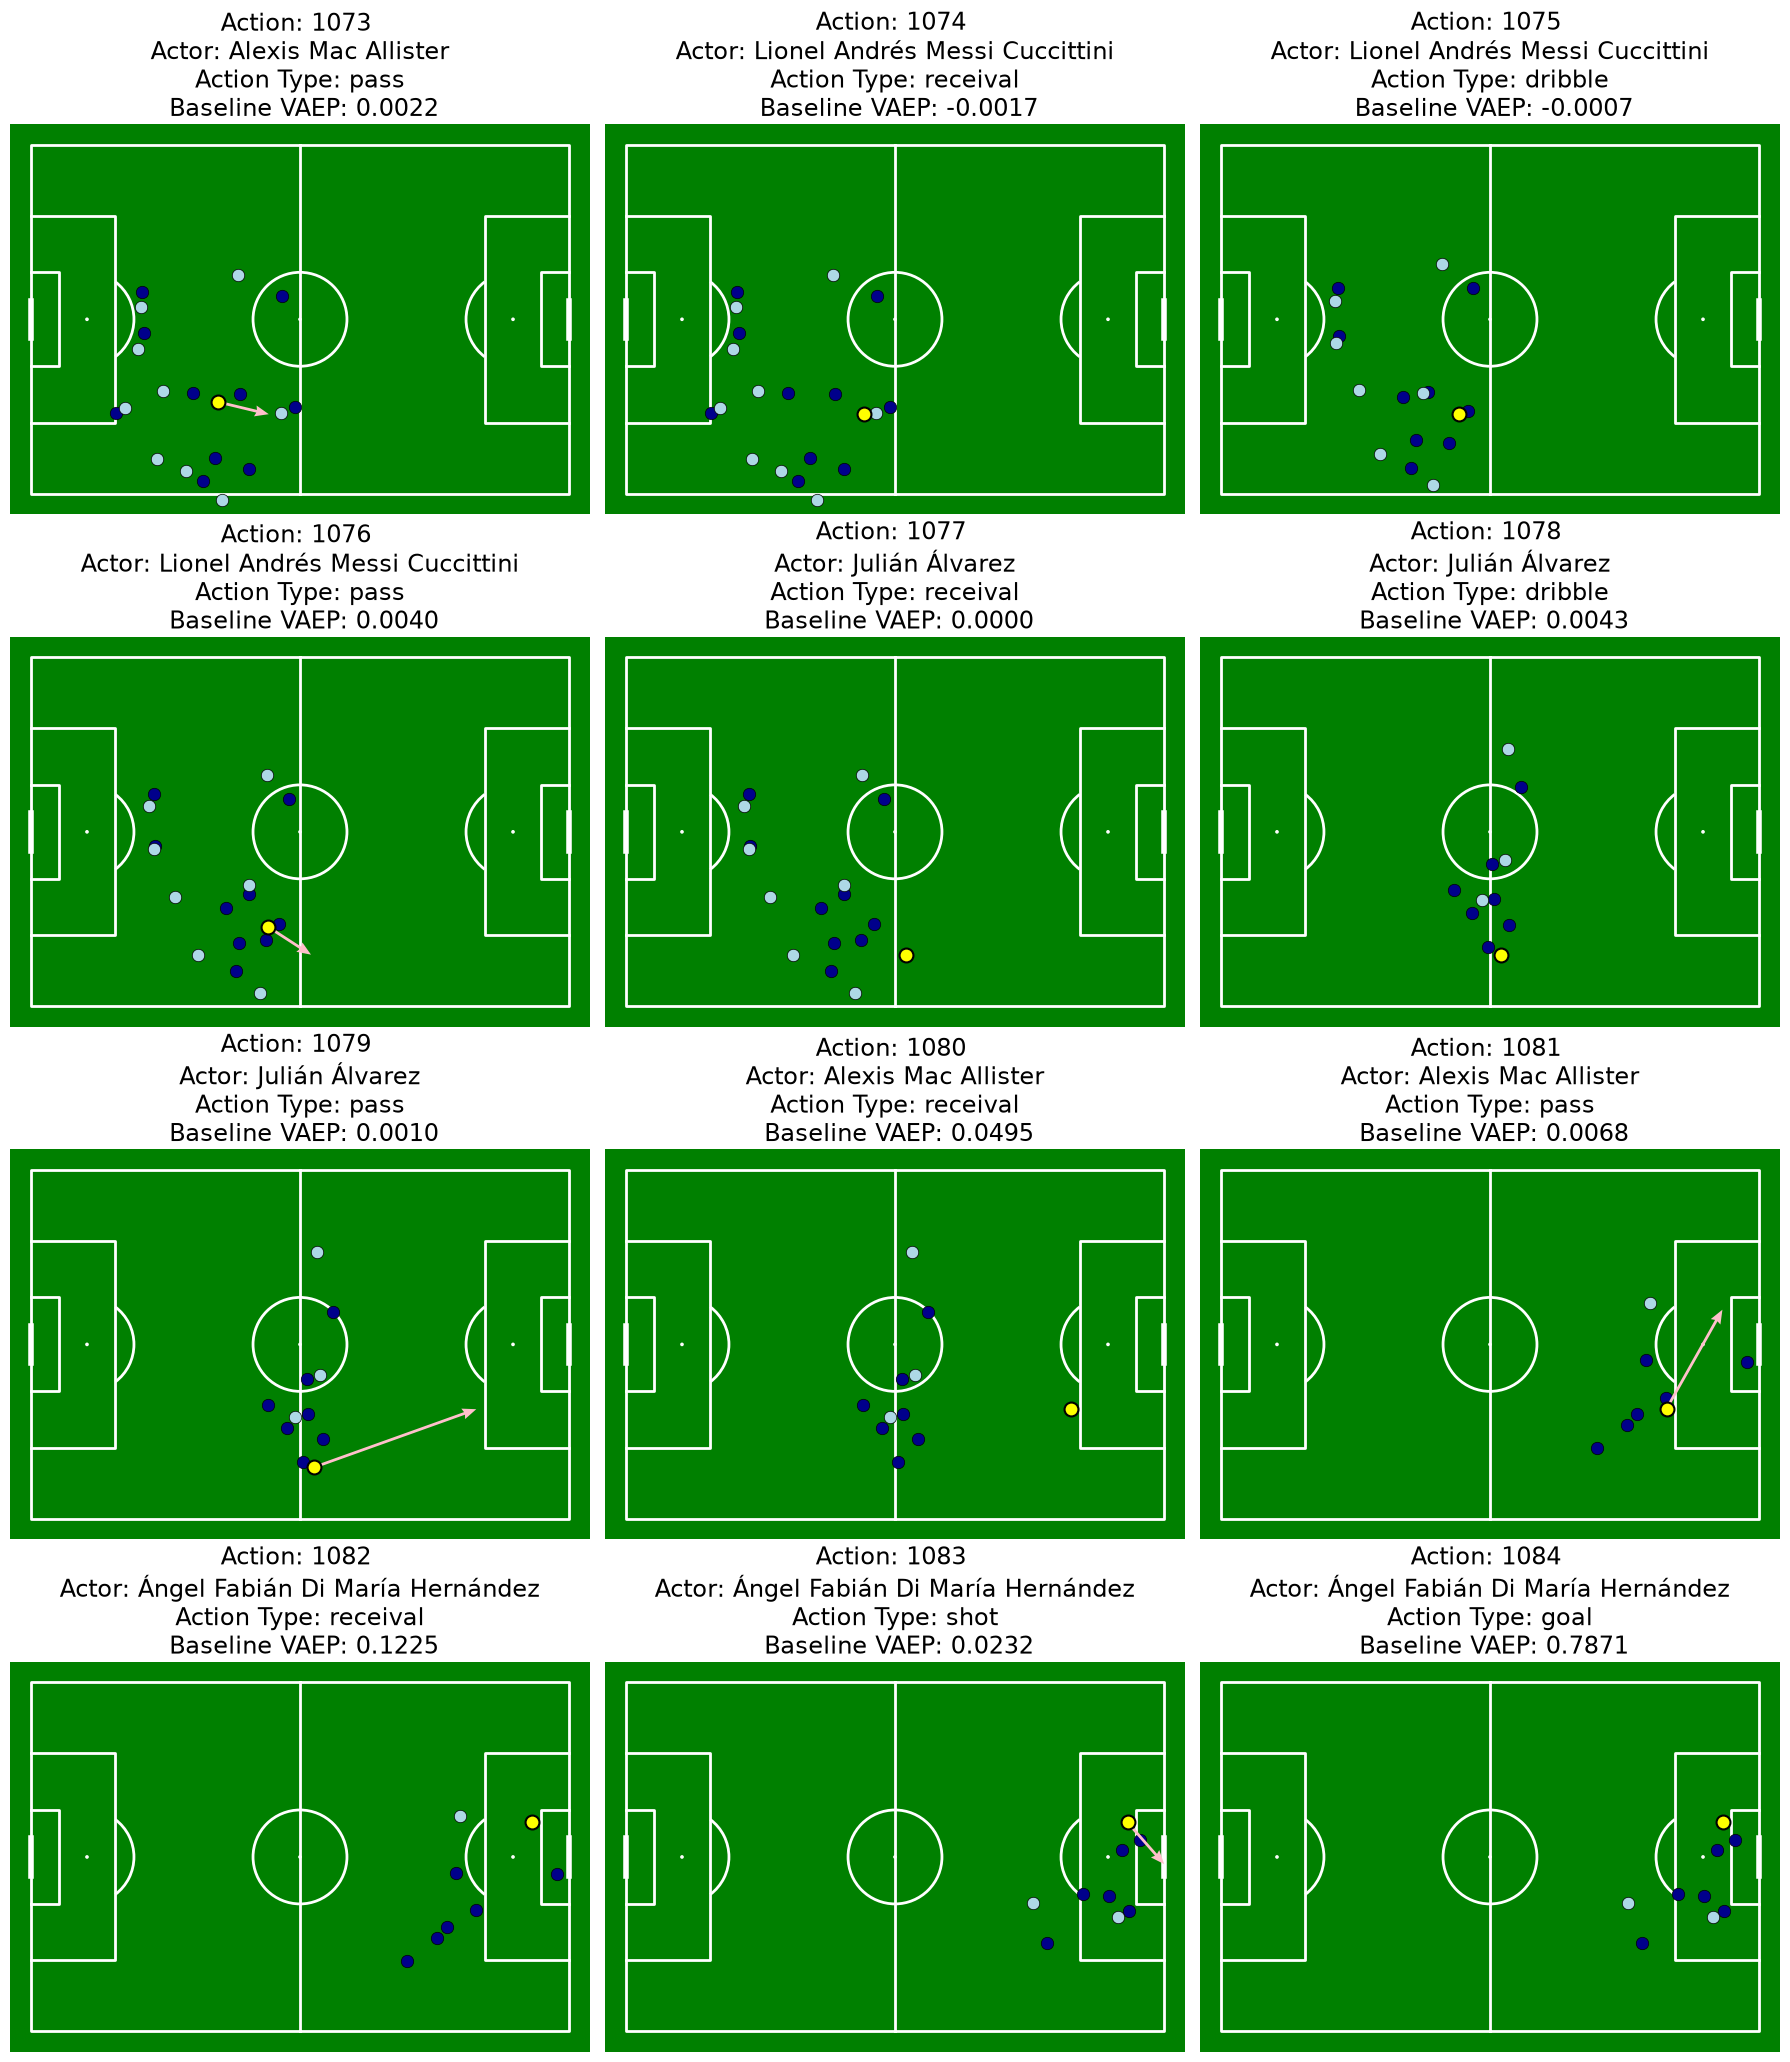

In [ ]:
pitch = Pitch(
    pitch_type="custom",
    pitch_length=105,
    pitch_width=68,
    pitch_color="green",
    line_color="white"
)

n_actions = len(game_example_actions_df.iloc[2:])

fig, axes = plt.subplots(
    4,
    3,
    figsize=(18, 21)
)

axes = axes.flatten()

for i, (_, action) in enumerate(
    game_example_actions_df.iloc[2:].iterrows()
):

    ax = axes[i]

    pitch.draw(ax=ax)

    action_id = action["action_id"]

    ff = freeze_df[
        freeze_df["action_id"] == action_id
    ].copy()

    opponents = ff[
        (~ff["teammate"]) &
        (~ff["actor"])
    ]

    pitch.scatter(
        opponents["x"],
        opponents["y"],
        s=80,
        color="darkblue",
        edgecolor="black",
        linewidth=0.5,
        ax=ax,
        zorder=2
    )

    teammates = ff[
        ff["teammate"] &
        (~ff["actor"])
    ]

    pitch.scatter(
        teammates["x"],
        teammates["y"],
        s=80,
        color="lightblue",
        edgecolor="black",
        linewidth=0.5,
        ax=ax,
        zorder=2
    )

    if action["type_name"] == "receival":

        actor_x = action["x"]
        actor_y = action["y"]

    else:

        actor = ff[ff["actor"]]

        actor_x = actor["x"].iloc[0]
        actor_y = actor["y"].iloc[0]

    pitch.scatter(
        actor_x,
        actor_y,
        s=100,
        color="yellow",
        edgecolor="black",
        linewidth=1.5,
        ax=ax,
        zorder=4
    )

    if action["type_name"] in ["pass", "dribble", "shot"]:

        pitch.arrows(
            action["x"],
            action["y"],
            action["x_end"],
            action["y_end"],
            color="pink",
            width=2,
            headwidth=4,
            headlength=5,
            ax=ax,
            zorder=3
        )

    ax.set_title(
        f'Action: {action["action_id"]} \n Actor: {action["player"]} \n Action Type: {action["type_name"]} \n Baseline VAEP: {action["vaep_value_baseline"]:.4f}',
        fontsize=17
    )

for ax in axes[n_actions:]:
    ax.remove()

plt.tight_layout()
plt.savefig("../reports/dissertation/figures/action_sequence.png", dpi=300)
plt.show()

In [ ]:
game_example_actions_df.iloc[2:][[
    "action_id", "player", "type_name", 
    "vaep_value_logistic_regression", "vaep_value_random_forest", 
    "vaep_value_catboost", "vaep_value_xgboost"
]].to_parquet(
    "../results/action_sequence_vaep_values_techniques.parquet",
    compression="zstd",
    index=False
)